# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


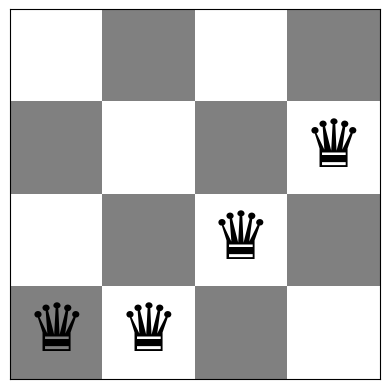

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


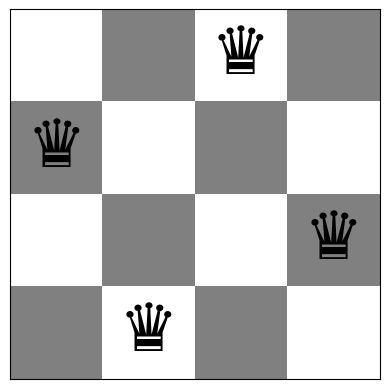

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [5]:
def steepest_ascent_hill_climbing(initial_board, max_steps=1000):
    """
    Steepest-Ascent Hill Climbing Search.
    Evaluates all n * (n - 1) possible single-queen moves, choosing the best move.
    Stops when no neighbor has strictly fewer conflicts than the current state (local optimum).
    """
    current = initial_board.copy()
    current_h = conflicts(current)
    evals = 1
    steps = 0
    n = len(current)
    
    while steps < max_steps and current_h > 0:
        best_neighbor = None
        best_h = current_h
        
        for c in range(n):
            for r in range(n):
                if r != current[c]:
                    neighbor = current.copy()
                    neighbor[c] = r
                    h = conflicts(neighbor)
                    evals += 1
                    if h < best_h:
                        best_h = h
                        best_neighbor = neighbor
                        
        if best_neighbor is None or best_h >= current_h:
            break
            
        current = best_neighbor
        current_h = best_h
        steps += 1
        
    return current, current_h, steps, evals

# Chạy thử 1 lần trên bàn cờ n=8
board_8 = random_board(8)
final_b, final_h, steps, evals = steepest_ascent_hill_climbing(board_8)
print(f"Steepest-Ascent: Conflicts ban đầu = {conflicts(board_8)} -> Kết thúc = {final_h} sau {steps} bước ({evals} evaluations)")


Steepest-Ascent: Conflicts ban đầu = 8 -> Kết thúc = 0 sau 5 bước (281 evaluations)


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [6]:
def inefficient_stochastic_hill_climbing(initial_board, max_steps=1000):
    """
    Inefficient Stochastic Hill Climbing Search.
    Evaluates all n * (n - 1) possible moves, collects all improving moves,
    and randomly chooses one. Stops when no improving move exists.
    """
    current = initial_board.copy()
    current_h = conflicts(current)
    evals = 1
    steps = 0
    n = len(current)
    
    while steps < max_steps and current_h > 0:
        better_neighbors = []
        for c in range(n):
            for r in range(n):
                if r != current[c]:
                    neighbor = current.copy()
                    neighbor[c] = r
                    h = conflicts(neighbor)
                    evals += 1
                    if h < current_h:
                        better_neighbors.append((neighbor, h))
                        
        if not better_neighbors:
            break
            
        current, current_h = better_neighbors[np.random.randint(len(better_neighbors))]
        steps += 1
        
    return current, current_h, steps, evals

final_b2, final_h2, steps2, evals2 = inefficient_stochastic_hill_climbing(board_8)
print(f"Inefficient Stochastic: Conflicts ban đầu = {conflicts(board_8)} -> Kết thúc = {final_h2} sau {steps2} bước ({evals2} evaluations)")


Inefficient Stochastic: Conflicts ban đầu = 8 -> Kết thúc = 1 sau 4 bước (281 evaluations)


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [7]:
def efficient_stochastic_hill_climbing(initial_board, max_steps=5000):
    """
    Efficient Stochastic Hill Climbing (First-choice).
    Generates a single random neighbor at a time and accepts it immediately if it improves conflicts.
    Stops if no improvement is found after patience consecutive tries.
    """
    current = initial_board.copy()
    current_h = conflicts(current)
    evals = 1
    steps = 0
    n = len(current)
    patience = 3 * n * (n - 1)  # Threshold to cover almost all possible moves
    failed_tries = 0
    
    while steps < max_steps and failed_tries < patience and current_h > 0:
        c = np.random.randint(n)
        r = np.random.randint(n)
        while r == current[c]:
            r = np.random.randint(n)
            
        neighbor = current.copy()
        neighbor[c] = r
        h = conflicts(neighbor)
        evals += 1
        
        if h < current_h:
            current = neighbor
            current_h = h
            steps += 1
            failed_tries = 0
        else:
            failed_tries += 1
            
    return current, current_h, steps, evals

final_b3, final_h3, steps3, evals3 = efficient_stochastic_hill_climbing(board_8)
print(f"Efficient Stochastic: Conflicts ban đầu = {conflicts(board_8)} -> Kết thúc = {final_h3} sau {steps3} bước ({evals3} evaluations)")


Efficient Stochastic: Conflicts ban đầu = 8 -> Kết thúc = 2 sau 5 bước (195 evaluations)


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [8]:
import time

def random_restart_hill_climbing(algorithm_fn, n=8, max_restarts=100):
    """
    Khởi động lại thuật toán Hill Climbing với các bàn cờ ngẫu nhiên mới,
    tối đa max_restarts lần. Dừng ngay khi đạt nghiệm tối ưu toàn cục (h = 0).
    Phân biệt rõ: Thành công (h = 0) vs Nghiệm tốt nhất từng gặp (h nhỏ nhất).
    """
    total_evals = 0
    total_steps = 0
    best_overall_h = float('inf')
    best_overall_board = None
    restarts_used = 0
    success = False
    
    t0 = time.perf_counter()
    for r in range(1, max_restarts + 1):
        restarts_used = r
        init_board = random_board(n)
        res_board, res_h, steps, evals = algorithm_fn(init_board)
        
        total_steps += steps
        total_evals += evals
        
        if res_h < best_overall_h:
            best_overall_h = res_h
            best_overall_board = res_board.copy()
            
        if res_h == 0:
            success = True
            break
            
    t1 = time.perf_counter()
    return {
        'success': success,
        'restarts': restarts_used,
        'best_h': best_overall_h,
        'best_board': best_overall_board,
        'total_steps': total_steps,
        'total_evals': total_evals,
        'time_ms': (t1 - t0) * 1000
    }

# Thống kê thử nghiệm trên 30 lần chạy với tối đa 100 lần restart (n = 8)
n = 8
num_runs = 30
algorithms = [
    ("Steepest-Ascent HC", steepest_ascent_hill_climbing),
    ("Inefficient Stochastic HC", inefficient_stochastic_hill_climbing),
    ("Efficient Stochastic HC", efficient_stochastic_hill_climbing)
]

print("=== TASK 4: KẾT QUẢ RANDOM RESTART (Tối đa 100 lần khởi động lại, n = 8) ===")
results_task4 = {}
for name, algo in algorithms:
    succ_list = []
    restarts_list = []
    evals_list = []
    times_list = []
    best_h_list = []
    
    for _ in range(num_runs):
        res = random_restart_hill_climbing(algo, n=n, max_restarts=100)
        succ_list.append(res['success'])
        restarts_list.append(res['restarts'])
        evals_list.append(res['total_evals'])
        times_list.append(res['time_ms'])
        best_h_list.append(res['best_h'])
        
    results_task4[name] = {
        'succ_rate': np.mean(succ_list) * 100,
        'avg_restarts': np.mean(restarts_list),
        'avg_evals': np.mean(evals_list),
        'avg_time': np.mean(times_list),
        'avg_best_h': np.mean(best_h_list)
    }
    print(f"- {name:27s} | Thành công: {results_task4[name]['succ_rate']:5.1f}% | Restarts TB: {results_task4[name]['avg_restarts']:4.1f} | Evals TB: {results_task4[name]['avg_evals']:6.0f} | Thời gian: {results_task4[name]['avg_time']:5.1f} ms")


=== TASK 4: KẾT QUẢ RANDOM RESTART (Tối đa 100 lần khởi động lại, n = 8) ===
- Steepest-Ascent HC          | Thành công: 100.0% | Restarts TB:  4.6 | Evals TB:   1080 | Thời gian:   9.2 ms
- Inefficient Stochastic HC   | Thành công: 100.0% | Restarts TB:  7.6 | Evals TB:   2485 | Thời gian:  21.1 ms
- Efficient Stochastic HC     | Thành công: 100.0% | Restarts TB:  6.5 | Evals TB:   1365 | Thời gian:  17.0 ms


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

=== TASK 5: SO SÁNH HAI LỊCH LÀM NGUỘI CỦA SIMULATED ANNEALING (n = 8) ===
- Geometric Cooling (T0=20, alpha=0.995)     | Thành công (h=0):  88.0% | Nghiệm tốt nhất TB (h): 0.12 | Evals TB:  1308 | Thời gian:  18.4 ms
- Linear Cooling (T0=20, max_iter=2500)      | Thành công (h=0):   8.0% | Nghiệm tốt nhất TB (h): 1.06 | Evals TB:  2458 | Thời gian:  33.4 ms


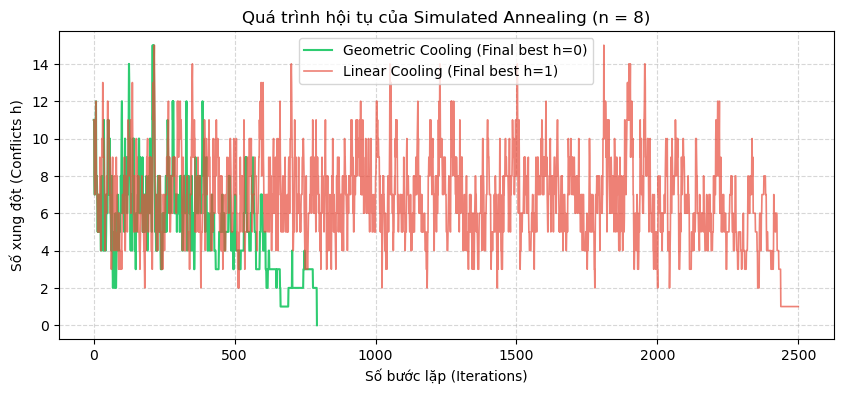

In [10]:
def simulated_annealing(n=8, schedule='geometric', T0=20.0, max_iter=2500, alpha=0.995, seed=None):
    """
    Simulated Annealing cho bài toán n-Queens.
    Chấp nhận bước đi tệ hơn (Delta h > 0) với xác suất p = exp(-Delta h / T).
    Hỗ trợ 2 lịch làm nguội:
      - 'geometric': T_k = T0 * (alpha ^ k)
      - 'linear':    T_k = max(T_min, T0 * (1 - k / max_iter))
    """
    if seed is not None:
        np.random.seed(seed)
        
    current = random_board(n)
    current_h = conflicts(current)
    best_board = current.copy()
    best_h = current_h
    
    history_h = [current_h]
    evals = 1
    t0 = time.perf_counter()
    
    for k in range(max_iter):
        if best_h == 0:
            break
            
        # 1. Tính nhiệt độ theo lịch làm nguội
        if schedule == 'geometric':
            T = T0 * (alpha ** k)
        elif schedule == 'linear':
            T = max(1e-4, T0 * (1.0 - k / max_iter))
        else:
            raise ValueError(f"Unknown schedule: {schedule}")
            
        # 2. Sinh láng giềng ngẫu nhiên
        c = np.random.randint(n)
        r = np.random.randint(n)
        while r == current[c]:
            r = np.random.randint(n)
            
        neighbor = current.copy()
        neighbor[c] = r
        h_next = conflicts(neighbor)
        evals += 1
        
        delta_h = h_next - current_h
        
        # 3. Tiêu chuẩn chấp nhận Metropolis
        if delta_h <= 0:
            current = neighbor
            current_h = h_next
            if current_h < best_h:
                best_h = current_h
                best_board = current.copy()
        else:
            if T > 1e-6:
                prob = np.exp(-delta_h / T)
                if np.random.rand() < prob:
                    current = neighbor
                    current_h = h_next
                    
        history_h.append(current_h)
        
    t1 = time.perf_counter()
    return {
        'success': (best_h == 0),
        'best_h': best_h,
        'best_board': best_board,
        'iterations': k + 1,
        'evals': evals,
        'time_ms': (t1 - t0) * 1000,
        'history': history_h
    }

# 1. So sánh 2 lịch làm nguội trên 50 lần chạy ngẫu nhiên (n = 8)
print("=== TASK 5: SO SÁNH HAI LỊCH LÀM NGUỘI CỦA SIMULATED ANNEALING (n = 8) ===")
schedules = [('Geometric Cooling (T0=20, alpha=0.995)', 'geometric'),
             ('Linear Cooling (T0=20, max_iter=2500)', 'linear')]

for label, sched_type in schedules:
    succ_cnt = 0
    best_hs = []
    evals_cnt = []
    times_cnt = []
    for s in range(50):
        res = simulated_annealing(n=8, schedule=sched_type, seed=s)
        if res['success']:
            succ_cnt += 1
        best_hs.append(res['best_h'])
        evals_cnt.append(res['evals'])
        times_cnt.append(res['time_ms'])
    print(f"- {label:42s} | Thành công (h=0): {succ_cnt/50*100:5.1f}% | Nghiệm tốt nhất TB (h): {np.mean(best_hs):.2f} | Evals TB: {np.mean(evals_cnt):5.0f} | Thời gian: {np.mean(times_cnt):5.1f} ms")

# 2. Vẽ biểu đồ quá trình hội tụ (Convergence curves)
plt.figure(figsize=(10, 4))
res_geom = simulated_annealing(n=8, schedule='geometric', seed=12)
res_linear = simulated_annealing(n=8, schedule='linear', seed=12)

plt.plot(res_geom['history'], label=f"Geometric Cooling (Final best h={res_geom['best_h']})", color="#2ecc71", lw=1.5)
plt.plot(res_linear['history'], label=f"Linear Cooling (Final best h={res_linear['best_h']})", color="#e74c3c", alpha=0.7, lw=1.2)
plt.xlabel("Số bước lặp (Iterations)")
plt.ylabel("Số xung đột (Conflicts h)")
plt.title("Quá trình hội tụ của Simulated Annealing (n = 8)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [10]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [11]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [12]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [13]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [14]:
# Code and description go here